# 1️⃣ PROBLEM UNDERSTANDING

## 1 — K-Means Clustering

Segment customers into distinct groups based on their **annual income and total spending behavior** to understand different customer value segments.

## 2 — Hierarchical Clustering

Identify groups of customers with **similar annual income and spending patterns** using hierarchical clustering.

## 3 — DBSCAN Clustering

Identify customers with **unusual income and spending patterns** using density-based clustering.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
# (2.) DATA UNDERSTANDING

df = pd.read_csv("customer_segmentation_dataset.csv") 
df.head()

,Customer_ID,Birth_Year,Education_Level,Marital_Status,Annual_Income,Kids_Home,Teens_Home,Customer_Since,Last_Purchase_Recency,Spent_Wine,...,Mobile_App_User,Email_Subscriber,Device_Type,Referred_By_Friend,Social_Media_User,Membership_Tier,Total_Amount_Spent,Customer_Age,Family_Size,Senior_Citizen
0,1,1978,Graduation,Widow,40175.23,1,1,26-09-2010,68,440,...,1,0,Desktop,1,1,Silver,1265,47,2,0
1,2,1991,PhD,Widow,27979.68,0,1,03-11-2012,99,826,...,1,1,Desktop,1,0,Basic,1647,34,1,0
2,3,1968,PhD,Married,64747.68,0,0,31-10-2013,63,895,...,0,0,Desktop,0,1,Silver,1806,57,1,0
3,4,1954,Graduation,Widow,50185.85,2,2,30-04-2010,65,127,...,0,1,Mobile,0,1,Basic,1207,71,4,1
4,5,1982,Graduation,Married,53163.09,1,2,25-09-2015,49,140,...,0,1,Mobile,1,1,Basic,934,43,4,0


In [3]:
df.shape

(10000, 42)

In [4]:
df.columns

Index(['Customer_ID', 'Birth_Year', 'Education_Level', 'Marital_Status',
       'Annual_Income', 'Kids_Home', 'Teens_Home', 'Customer_Since',
       'Last_Purchase_Recency', 'Spent_Wine', 'Spent_Fruits', 'Spent_Meat',
       'Spent_Fish', 'Spent_Sweets', 'Spent_Gold', 'Deals_Purchased',
       'Web_Purchases', 'Catalog_Purchases', 'Store_Purchases',
       'Monthly_Web_Visits', 'Campaign1_Accepted', 'Campaign2_Accepted',
       'Campaign3_Accepted', 'Campaign4_Accepted', 'Campaign5_Accepted',
       'Filed_Complaint', 'Contact_Cost', 'Revenue_Contribution',
       'Campaign_Response', 'Country', 'City', 'Region_Code',
       'Mobile_App_User', 'Email_Subscriber', 'Device_Type',
       'Referred_By_Friend', 'Social_Media_User', 'Membership_Tier',
       'Total_Amount_Spent', 'Customer_Age', 'Family_Size', 'Senior_Citizen'],
      dtype='str')

In [5]:
df.dtypes

Customer_ID                int64
Birth_Year                 int64
Education_Level              str
Marital_Status               str
Annual_Income            float64
Kids_Home                  int64
Teens_Home                 int64
Customer_Since               str
Last_Purchase_Recency      int64
Spent_Wine                 int64
Spent_Fruits               int64
Spent_Meat                 int64
Spent_Fish                 int64
Spent_Sweets               int64
Spent_Gold                 int64
Deals_Purchased            int64
Web_Purchases              int64
Catalog_Purchases          int64
Store_Purchases            int64
Monthly_Web_Visits         int64
Campaign1_Accepted         int64
Campaign2_Accepted         int64
Campaign3_Accepted         int64
Campaign4_Accepted         int64
Campaign5_Accepted         int64
Filed_Complaint            int64
Contact_Cost               int64
Revenue_Contribution       int64
Campaign_Response          int64
Country                      str
City      

In [6]:
# numerical columns

numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical Columns Count:", numerical_columns.value_counts().sum())

print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns Count: 35
Numerical Columns:
['Customer_ID', 'Birth_Year', 'Annual_Income', 'Kids_Home', 'Teens_Home', 'Last_Purchase_Recency', 'Spent_Wine', 'Spent_Fruits', 'Spent_Meat', 'Spent_Fish', 'Spent_Sweets', 'Spent_Gold', 'Deals_Purchased', 'Web_Purchases', 'Catalog_Purchases', 'Store_Purchases', 'Monthly_Web_Visits', 'Campaign1_Accepted', 'Campaign2_Accepted', 'Campaign3_Accepted', 'Campaign4_Accepted', 'Campaign5_Accepted', 'Filed_Complaint', 'Contact_Cost', 'Revenue_Contribution', 'Campaign_Response', 'Region_Code', 'Mobile_App_User', 'Email_Subscriber', 'Referred_By_Friend', 'Social_Media_User', 'Total_Amount_Spent', 'Customer_Age', 'Family_Size', 'Senior_Citizen']


In [7]:
# Categorical columns 

categorical_columns = df.select_dtypes(include=["category","object"]).columns

print("Categorical columns Count:", categorical_columns.value_counts().sum())

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical columns Count: 7
Categorical Columns:
['Education_Level', 'Marital_Status', 'Customer_Since', 'Country', 'City', 'Device_Type', 'Membership_Tier']


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3424\822250909.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["category","object"]).columns


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 42 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  int64  
 1   Birth_Year             10000 non-null  int64  
 2   Education_Level        10000 non-null  str    
 3   Marital_Status         10000 non-null  str    
 4   Annual_Income          10000 non-null  float64
 5   Kids_Home              10000 non-null  int64  
 6   Teens_Home             10000 non-null  int64  
 7   Customer_Since         10000 non-null  str    
 8   Last_Purchase_Recency  10000 non-null  int64  
 9   Spent_Wine             10000 non-null  int64  
 10  Spent_Fruits           10000 non-null  int64  
 11  Spent_Meat             10000 non-null  int64  
 12  Spent_Fish             10000 non-null  int64  
 13  Spent_Sweets           10000 non-null  int64  
 14  Spent_Gold             10000 non-null  int64  
 15  Deals_Purchase

In [9]:
df.describe()

,Customer_ID,Birth_Year,Annual_Income,Kids_Home,Teens_Home,Last_Purchase_Recency,Spent_Wine,Spent_Fruits,Spent_Meat,Spent_Fish,...,Campaign_Response,Region_Code,Mobile_App_User,Email_Subscriber,Referred_By_Friend,Social_Media_User,Total_Amount_Spent,Customer_Age,Family_Size,Senior_Citizen
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1970.798400,49934.047232,0.997300,0.989300,49.592500,497.928400,49.709000,401.292100,148.804400,...,0.502500,551.009400,0.494000,0.511400,0.504200,0.500600,1447.778100,54.201600,2.375000,0.400700
std,2886.89568,17.903223,14870.373127,0.818388,0.814894,29.101686,287.932884,28.852961,230.822103,86.715667,...,0.500019,258.756758,0.499989,0.499895,0.500007,0.500025,408.159165,17.903223,1.248812,0.490065
min,1.00000,1940.000000,-7845.630000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000,210.000000,24.000000,0.000000,0.000000
25%,2500.75000,1956.000000,39607.725000,0.000000,0.000000,25.000000,245.000000,25.000000,202.000000,73.000000,...,0.000000,327.000000,0.000000,0.000000,0.000000,0.000000,1158.750000,39.000000,1.000000,0.000000
50%,5000.50000,1971.000000,49966.965000,1.000000,1.000000,49.000000,500.000000,49.000000,406.000000,148.000000,...,1.000000,550.500000,0.000000,1.000000,1.000000,1.000000,1447.000000,54.000000,2.000000,0.000000
75%,7500.25000,1986.000000,60058.947500,2.000000,2.000000,75.000000,747.000000,75.000000,600.000000,223.000000,...,1.000000,778.000000,1.000000,1.000000,1.000000,1.000000,1736.000000,69.000000,3.000000,1.000000
max,10000.00000,2001.000000,109134.970000,2.000000,2.000000,99.000000,999.000000,99.000000,799.000000,299.000000,...,1.000000,998.000000,1.000000,1.000000,1.000000,1.000000,2684.000000,85.000000,5.000000,1.000000


In [10]:
# (3.) DATA CLEANING  

# missing values 

missing_values = df.isnull().sum().sum()
print("Total Missing Values:", missing_values)

Total Missing Values: 0


In [11]:
# Duplicate rows 

duplicate_count = df.duplicated().sum()
print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 0


In [12]:
# Unique values 

unique_counts = df.nunique().sort_values()
print(unique_counts)

Revenue_Contribution         1
Contact_Cost                 1
Campaign1_Accepted           2
Campaign2_Accepted           2
Campaign3_Accepted           2
Campaign4_Accepted           2
Filed_Complaint              2
Campaign5_Accepted           2
Campaign_Response            2
Referred_By_Friend           2
Email_Subscriber             2
Senior_Citizen               2
Social_Media_User            2
Mobile_App_User              2
Kids_Home                    3
Teens_Home                   3
Device_Type                  3
Membership_Tier              4
Education_Level              4
Country                      5
Marital_Status               5
City                         5
Family_Size                  6
Deals_Purchased             10
Store_Purchases             10
Web_Purchases               10
Catalog_Purchases           10
Monthly_Web_Visits          20
Birth_Year                  62
Customer_Age                62
Spent_Fruits               100
Last_Purchase_Recency      100
Spent_Sw

In [13]:
# Invalid values 

negative_values = {}

for column in numerical_columns:
    count = (df[column] < 0).sum()
    
    if count > 0:
        negative_values[column] = count

print(negative_values)


{'Annual_Income': np.int64(5)}


In [14]:
print(
    df[df["Annual_Income"] < 0][
        ["Customer_ID", "Annual_Income"]
    ]
)

      Customer_ID  Annual_Income
16             17         -38.52
1476         1477       -7845.63
1654         1655         -23.39
4296         4297       -4826.30
6413         6414       -2425.68


In [15]:
# replace missing values 

median_income = df["Annual_Income"].median()

df.loc[
    df["Annual_Income"] < 0,
    "Annual_Income"
] = median_income

print("Median Annual Income:", median_income)
print("Negative Annual Income values:",
      (df["Annual_Income"] < 0).sum())

Median Annual Income: 49966.965
Negative Annual Income values: 0


In [16]:
# Outliers detection 

outlier_summary = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()
    
    outlier_summary[column] = outlier_count

outlier_summary = pd.Series(outlier_summary).sort_values(
    ascending=False
)

print(outlier_summary) 

Annual_Income            52
Total_Amount_Spent        6
Customer_ID               0
Birth_Year                0
Kids_Home                 0
Last_Purchase_Recency     0
Teens_Home                0
Spent_Fruits              0
Spent_Meat                0
Spent_Fish                0
Spent_Wine                0
Spent_Gold                0
Deals_Purchased           0
Web_Purchases             0
Catalog_Purchases         0
Store_Purchases           0
Monthly_Web_Visits        0
Campaign1_Accepted        0
Spent_Sweets              0
Campaign2_Accepted        0
Campaign3_Accepted        0
Campaign5_Accepted        0
Campaign4_Accepted        0
Contact_Cost              0
Revenue_Contribution      0
Campaign_Response         0
Filed_Complaint           0
Region_Code               0
Mobile_App_User           0
Referred_By_Friend        0
Email_Subscriber          0
Social_Media_User         0
Customer_Age              0
Family_Size               0
Senior_Citizen            0
dtype: int64


In [17]:
# handling outliers 

Q1 = df["Annual_Income"].quantile(0.25)
Q3 = df["Annual_Income"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound) 

print("-------------------------------------------") 

income_outliers = df[
    (df["Annual_Income"] < lower_bound) |
    (df["Annual_Income"] > upper_bound)
]

print("Annual Income Outliers:", len(income_outliers))

Q1: 39643.28
Q3: 60058.9475
IQR: 20415.667500000003
Lower Bound: 9019.778749999994
Upper Bound: 90682.44875000001
-------------------------------------------
Annual Income Outliers: 52


In [18]:
income_outliers[
    [
        "Customer_ID",
        "Annual_Income",
        "Customer_Age",
        "Total_Amount_Spent",
        "Membership_Tier"
    ]
].head(20)

,Customer_ID,Annual_Income,Customer_Age,Total_Amount_Spent,Membership_Tier
165,166,94957.97,49,1424,Silver
207,208,5359.51,57,2025,Gold
220,221,92705.14,29,1710,Silver
424,425,8877.66,83,1508,Basic
452,453,94072.82,26,1618,Basic
653,654,109134.97,50,1517,Basic
1040,1041,92594.34,41,1441,Silver
1181,1182,91748.53,64,1556,Basic
1187,1188,6326.75,25,1025,Gold
1292,1293,93954.80,55,1416,Silver


In [19]:
Q1 = df["Total_Amount_Spent"].quantile(0.25)
Q3 = df["Total_Amount_Spent"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("-----------------------------------------") 
spent_outliers = df[
    (df["Total_Amount_Spent"] < lower_bound) |
    (df["Total_Amount_Spent"] > upper_bound)
]

print("Total Amount Spent Outliers:", len(spent_outliers))

Q1: 1158.75
Q3: 1736.0
IQR: 577.25
Lower Bound: 292.875
Upper Bound: 2601.875
-----------------------------------------
Total Amount Spent Outliers: 6


In [20]:
spent_outliers[
    [
        "Customer_ID",
        "Total_Amount_Spent",
        "Annual_Income",
        "Spent_Wine",
        "Spent_Fruits",
        "Spent_Meat",
        "Spent_Fish",
        "Spent_Sweets",
        "Spent_Gold"
    ]
]

,Customer_ID,Total_Amount_Spent,Annual_Income,Spent_Wine,Spent_Fruits,Spent_Meat,Spent_Fish,Spent_Sweets,Spent_Gold
1088,1089,2614,48048.94,937,72,719,284,142,460
3476,3477,2623,63825.37,979,69,754,282,94,445
4368,4369,2684,24391.38,994,78,777,224,177,434
6253,6254,210,41138.29,37,20,90,9,5,49
8390,8391,2616,55516.82,925,39,764,267,168,453
8448,8449,247,47796.68,104,12,7,56,55,13


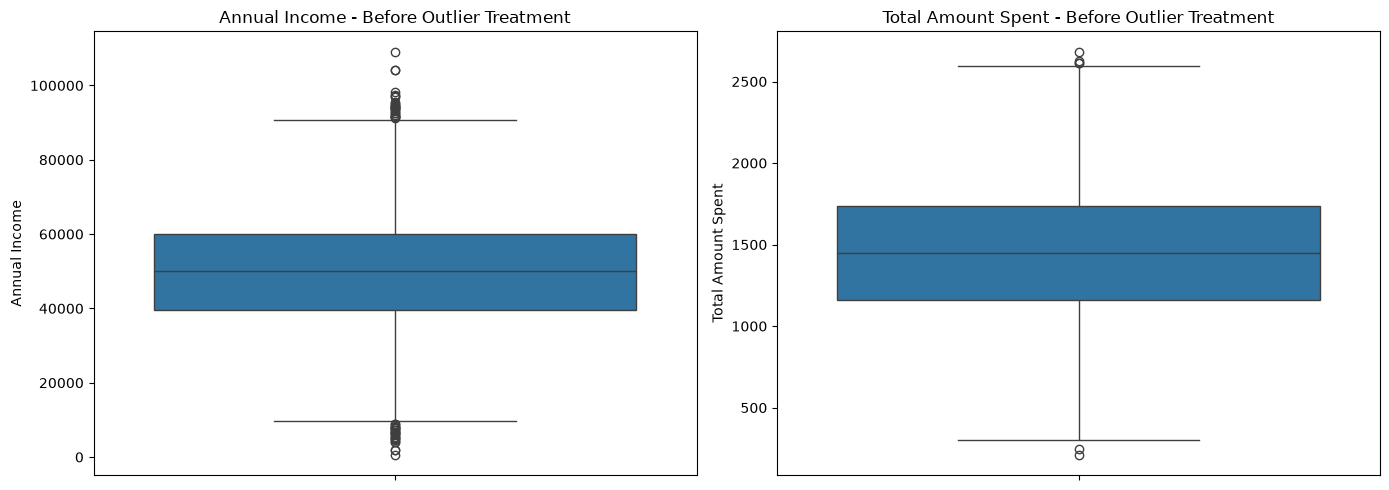

In [21]:
# Boxplots before outlier treatment

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["Annual_Income"], ax=axes[0])
axes[0].set_title("Annual Income - Before Outlier Treatment")
axes[0].set_ylabel("Annual Income")

sns.boxplot(y=df["Total_Amount_Spent"], ax=axes[1])
axes[1].set_title("Total Amount Spent - Before Outlier Treatment")
axes[1].set_ylabel("Total Amount Spent")

plt.tight_layout()
plt.show()

In [22]:
# Convert numerical columns to float
for column in numerical_columns:
    df[column] = df[column].astype(float)

# Replace outliers using original IQR boundaries
for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    median = df[column].median()

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    df.loc[outlier_mask, column] = median

In [23]:
outlier_summary = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_summary[column] = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

outlier_summary = pd.Series(outlier_summary)

print(outlier_summary[outlier_summary > 0])

Annual_Income    4
dtype: int64


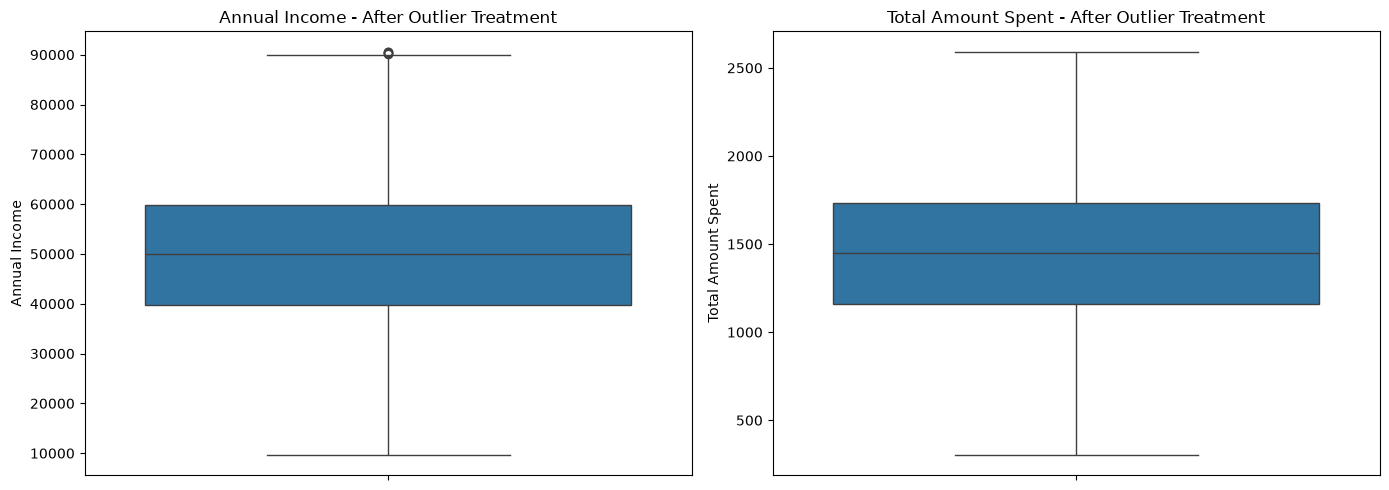

In [24]:
# Boxplots after outlier treatment

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["Annual_Income"], ax=axes[0])
axes[0].set_title("Annual Income - After Outlier Treatment")
axes[0].set_ylabel("Annual Income")

sns.boxplot(y=df["Total_Amount_Spent"], ax=axes[1])
axes[1].set_title("Total Amount Spent - After Outlier Treatment")
axes[1].set_ylabel("Total Amount Spent")

plt.tight_layout()
plt.show()

In [25]:
outlier_bounds = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    outlier_bounds[column] = {
        "lower": Q1 - 1.5 * IQR,
        "upper": Q3 + 1.5 * IQR
    }

In [26]:
outlier_bounds = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    outlier_bounds[column] = {
        "lower": Q1 - 1.5 * IQR,
        "upper": Q3 + 1.5 * IQR
    }

for column in numerical_columns:
    lower_bound = outlier_bounds[column]["lower"]
    upper_bound = outlier_bounds[column]["upper"]

    median = df[column].median()

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    df.loc[outlier_mask, column] = median

In [27]:
outlier_summary = {}

for column in numerical_columns:
    lower_bound = outlier_bounds[column]["lower"]
    upper_bound = outlier_bounds[column]["upper"]

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary[column] = outlier_count

outlier_summary = pd.Series(outlier_summary)

print(outlier_summary[outlier_summary > 0])

Series([], dtype: int64)


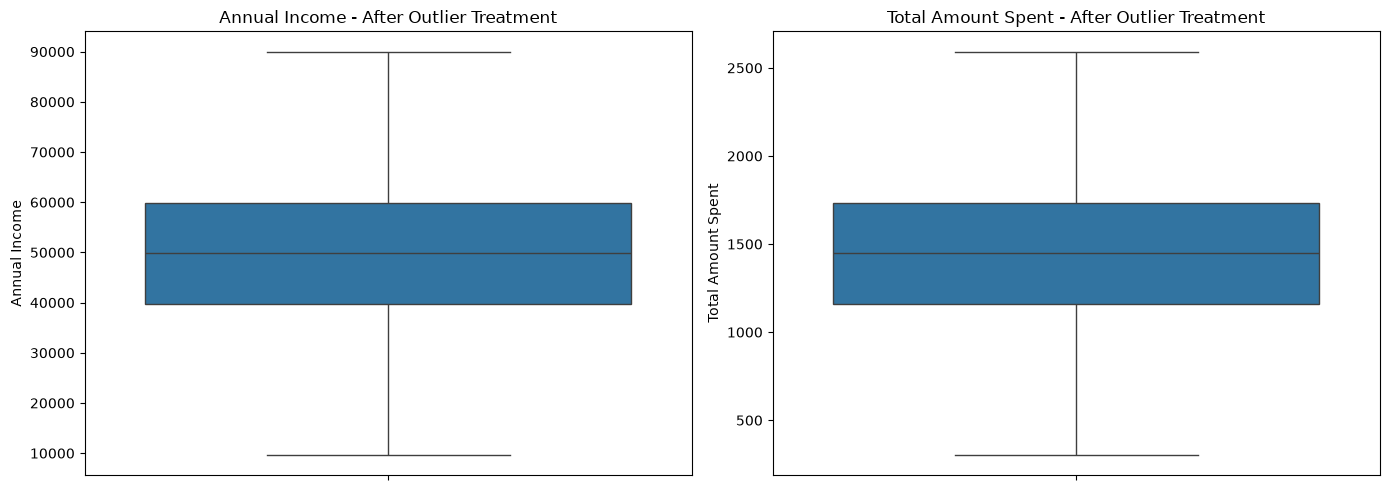

In [28]:
# Boxplots after outlier treatment

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["Annual_Income"], ax=axes[0])
axes[0].set_title("Annual Income - After Outlier Treatment")
axes[0].set_ylabel("Annual Income")

sns.boxplot(y=df["Total_Amount_Spent"], ax=axes[1])
axes[1].set_title("Total Amount Spent - After Outlier Treatment")
axes[1].set_ylabel("Total Amount Spent")

plt.tight_layout()
plt.show()

In [29]:
df.to_csv("customer_segmentation_cleaned.csv", index=False)

In [30]:
# REMOVE UNNECESSARY COLUMNS 

target_columns = [
    column for column in df.columns
    if column.lower() in ["target", "label", "churn", "class", "y"]
]

print("Target/Label columns:", target_columns)

print("-" * 50)

# Remove identifier column

df = df.drop(columns=["Customer_ID"])

print("Customer_ID" in df.columns)
print("Shape after removing ID:", df.shape)

Target/Label columns: []
--------------------------------------------------
False
Shape after removing ID: (10000, 41)


In [31]:
# 5. Feature Selection 

# Display all remaining features

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. Birth_Year
2. Education_Level
3. Marital_Status
4. Annual_Income
5. Kids_Home
6. Teens_Home
7. Customer_Since
8. Last_Purchase_Recency
9. Spent_Wine
10. Spent_Fruits
11. Spent_Meat
12. Spent_Fish
13. Spent_Sweets
14. Spent_Gold
15. Deals_Purchased
16. Web_Purchases
17. Catalog_Purchases
18. Store_Purchases
19. Monthly_Web_Visits
20. Campaign1_Accepted
21. Campaign2_Accepted
22. Campaign3_Accepted
23. Campaign4_Accepted
24. Campaign5_Accepted
25. Filed_Complaint
26. Contact_Cost
27. Revenue_Contribution
28. Campaign_Response
29. Country
30. City
31. Region_Code
32. Mobile_App_User
33. Email_Subscriber
34. Device_Type
35. Referred_By_Friend
36. Social_Media_User
37. Membership_Tier
38. Total_Amount_Spent
39. Customer_Age
40. Family_Size
41. Senior_Citizen


In [32]:
df = df.drop(columns=["Birth_Year"])             # We'll retain Customer_Age because it is more directly interpretable for segmentation.

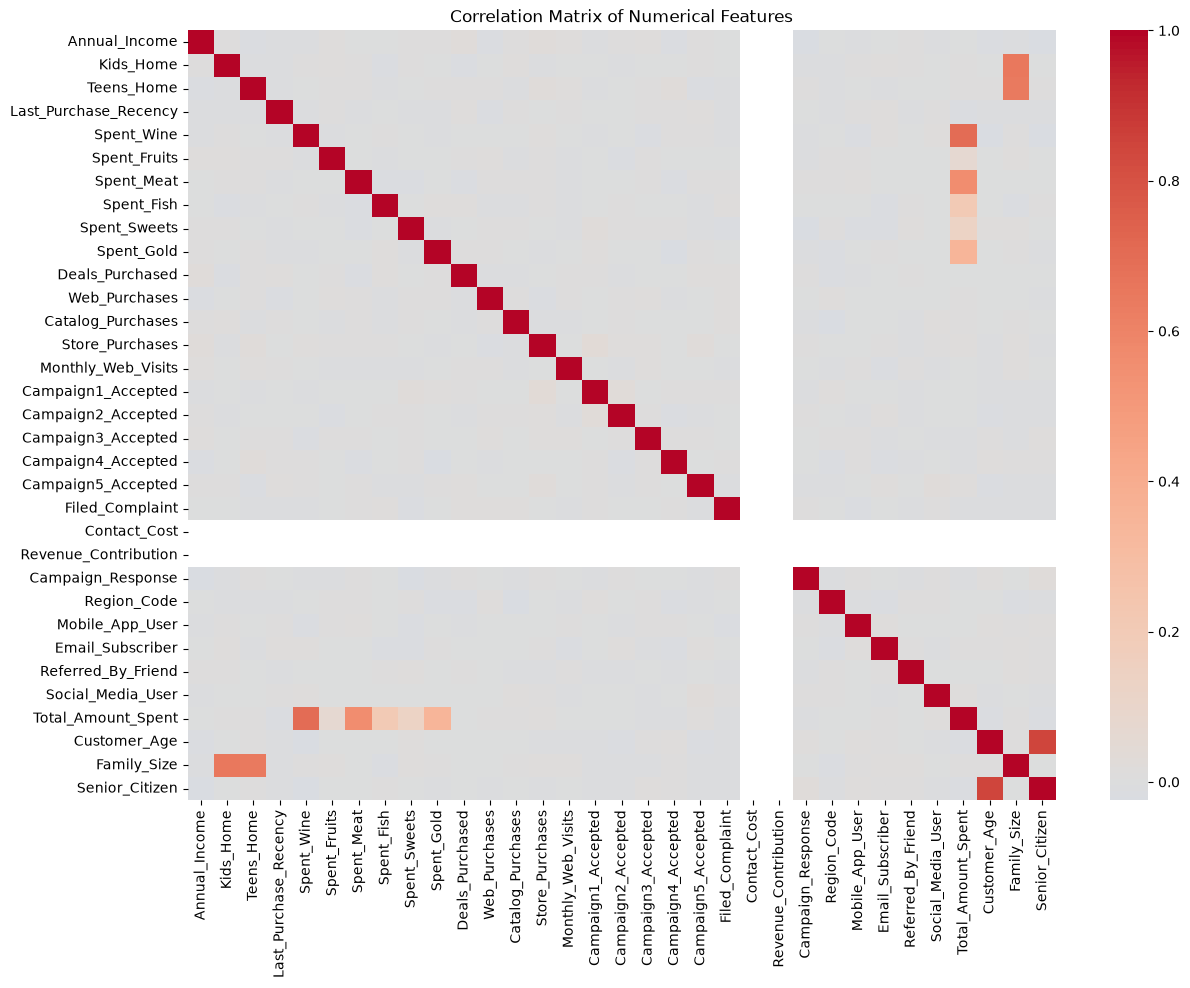

In [33]:
plt.figure(figsize=(14, 10))

correlation_matrix = df.select_dtypes(
    include=["int64", "float64", "float32", "float64"]
).corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [34]:
# Check features with only one unique value

constant_features = df.columns[df.nunique() <= 1]

print("Constant Features:")
print(list(constant_features))

Constant Features:
['Contact_Cost', 'Revenue_Contribution']


In [35]:
# Remove constant features

df = df.drop(columns=constant_features)

print("Removed Features:", list(constant_features))
print("Shape after removing constant features:", df.shape)

Removed Features: ['Contact_Cost', 'Revenue_Contribution']
Shape after removing constant features: (10000, 38)


In [36]:
# Identify highly correlated numerical features

numeric_df = df.select_dtypes(
    include=["int64", "float64", "float32"]
)

correlation_matrix = numeric_df.corr().abs()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlation = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation.columns = ["Feature_1", "Feature_2", "Correlation"]

high_correlation = high_correlation[
    high_correlation["Correlation"] >= 0.80
].sort_values("Correlation", ascending=False)

print(high_correlation)

        Feature_1       Feature_2  Correlation
898  Customer_Age  Senior_Citizen     0.847354


In [37]:
# Remove highly correlated redundant feature

df = df.drop(columns=["Senior_Citizen"])

print("Removed Feature: Senior_Citizen")        # Senior_Citizen was removed because it has a strong correlation of 0.847 with Customer_Age and provides overlapping information.
print("Shape:", df.shape)

Removed Feature: Senior_Citizen
Shape: (10000, 37)


In [38]:
# Check unique values in categorical features

categorical_columns = df.select_dtypes(include=["object"]).columns

categorical_cardinality = df[categorical_columns].nunique().sort_values(ascending=False)

print(categorical_cardinality)

Customer_Since     2168
Marital_Status        5
Country               5
City                  5
Education_Level       4
Membership_Tier       4
Device_Type           3
dtype: int64


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3424\1805938486.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object"]).columns


In [39]:
# Display categorical feature cardinality (count of unique values within a dataset column)

categorical_cardinality = df[categorical_columns].nunique().sort_values(ascending=False)

print(categorical_cardinality)

# can't perfrom one-hot encoding on 2168 elements, we need to convert to datetime data type.

Customer_Since     2168
Marital_Status        5
Country               5
City                  5
Education_Level       4
Membership_Tier       4
Device_Type           3
dtype: int64


In [40]:
# Convert Customer_Since to datetime

df["Customer_Since"] = pd.to_datetime(df["Customer_Since"])

print(df["Customer_Since"].dtype)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3424\4233600834.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Customer_Since"] = pd.to_datetime(df["Customer_Since"])


datetime64[us]


In [41]:
# Create Customer Tenure in years

reference_date = df["Customer_Since"].max()

df["Customer_Tenure_Years"] = (
    (reference_date - df["Customer_Since"]).dt.days / 365.25
)

print("Reference Date:", reference_date)
print(df["Customer_Tenure_Years"].head())

Reference Date: 2015-12-31 00:00:00
0    5.262149
1    3.156742
2    2.165640
3    5.670089
4    0.265572
Name: Customer_Tenure_Years, dtype: float64


In [42]:
# Check Customer Tenure statistics

print(df["Customer_Tenure_Years"].describe())

count    10000.000000
mean         3.015515
std          1.738639
min          0.000000
25%          1.503080
50%          3.017112
75%          4.536619
max          5.995893
Name: Customer_Tenure_Years, dtype: float64


In [43]:
# Remove original Customer_Since column

df = df.drop(columns=["Customer_Since"])

print("Customer_Since" in df.columns)
print("Shape:", df.shape)

False
Shape: (10000, 37)


In [44]:
# (6.) ENCODING 

numerical_features = df.select_dtypes(
    include=["int64", "float64", "float32"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist() 

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(
    df[categorical_features]
)

print("Encoded Shape:", encoded_data.shape)

Encoded Shape: (10000, 26)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3424\801582634.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [45]:
# Get encoded feature names

encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=df.index
)

encoded_df.head()

,Education_Level_Basic,Education_Level_Graduation,Education_Level_Master,Education_Level_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Country_Brazil,...,City_Mumbai,City_New York,City_São Paulo,Device_Type_Desktop,Device_Type_Mobile,Device_Type_Tablet,Membership_Tier_Basic,Membership_Tier_Gold,Membership_Tier_Platinum,Membership_Tier_Silver
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [46]:
# Combine numerical and encoded categorical features

X = pd.concat(
    [
        df[numerical_features],
        encoded_df
    ],
    axis=1
)

print("Final X Shape:", X.shape)
print("Missing Values:", X.isnull().sum().sum())

Final X Shape: (10000, 57)
Missing Values: 0


In [47]:
# (7.) Feature Scaling 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

print("Scaled X Shape:", X_scaled.shape)

Scaled X Shape: (10000, 57)


In [48]:
print("Mean of scaled features:")
print(X_scaled.mean().round(2).head())

print("\nStandard deviation of scaled features:")
print(X_scaled.std().round(2).head())

Mean of scaled features:
Annual_Income           -0.0
Kids_Home               -0.0
Teens_Home              -0.0
Last_Purchase_Recency   -0.0
Spent_Wine              -0.0
dtype: float64

Standard deviation of scaled features:
Annual_Income            1.0
Kids_Home                1.0
Teens_Home               1.0
Last_Purchase_Recency    1.0
Spent_Wine               1.0
dtype: float64


In [49]:
# (8.) FINAL DATA VALIDATION  

print("Final X Shape:", X_scaled.shape)
print("Total Missing Values:", X_scaled.isnull().sum().sum())
print("Total Duplicate Rows:", X_scaled.duplicated().sum()) 
print("-" * 70)
print("Infinite Values:", np.isinf(X_scaled).sum().sum())
print("-" * 70)
print("Mean range:", X_scaled.mean().min(), "to", X_scaled.mean().max())
print("Std range:", X_scaled.std().min(), "to", X_scaled.std().max())

Final X Shape: (10000, 57)
Total Missing Values: 0
Total Duplicate Rows: 0
----------------------------------------------------------------------
Infinite Values: 0
----------------------------------------------------------------------
Mean range: -1.9966250874858815e-16 to 1.5347723092418165e-16
Std range: 1.0000500037503124 to 1.0000500037503126


In [50]:
# (9.) PCA / DIMENSIONALITY REDUCTION 

from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X_scaled.shape[1])
print("PCA Components:", X_pca.shape[1])

Original Features: 57
PCA Components: 57


In [51]:
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

Explained Variance Ratio:
[3.60413177e-02 3.49645721e-02 3.21733488e-02 2.85629389e-02
 2.74774901e-02 2.36902263e-02 2.33454842e-02 2.31391947e-02
 2.28502970e-02 2.26197141e-02 2.23354510e-02 2.22401418e-02
 2.20220390e-02 2.20041334e-02 2.17211781e-02 2.15995558e-02
 2.12970165e-02 2.11366221e-02 2.09933239e-02 2.07783900e-02
 1.99016718e-02 1.97706581e-02 1.88042396e-02 1.86898674e-02
 1.85462917e-02 1.84375447e-02 1.83907215e-02 1.82800803e-02
 1.80823147e-02 1.80560087e-02 1.78386846e-02 1.77390472e-02
 1.76251895e-02 1.75134476e-02 1.74672749e-02 1.73836815e-02
 1.73083191e-02 1.72512255e-02 1.71388331e-02 1.69808846e-02
 1.69058786e-02 1.67970682e-02 1.66335007e-02 1.65791324e-02
 1.64996063e-02 1.63338866e-02 1.61398253e-02 1.59791730e-02
 1.58886706e-02 4.48370835e-05 1.56661889e-17 1.01131684e-17
 7.53715611e-18 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00]


In [52]:
cumulative_variance = np.cumsum(explained_variance)

print("Cumulative Explained Variance:")
print(cumulative_variance)

Cumulative Explained Variance:
[0.03604132 0.07100589 0.10317924 0.13174218 0.15921967 0.18290989
 0.20625538 0.22939457 0.25224487 0.27486458 0.29720003 0.31944018
 0.34146222 0.36346635 0.38518753 0.40678708 0.4280841  0.44922072
 0.47021405 0.49099244 0.51089411 0.53066477 0.549469   0.56815887
 0.58670516 0.60514271 0.62353343 0.64181351 0.65989583 0.67795183
 0.69579052 0.71352957 0.73115476 0.7486682  0.76613548 0.78351916
 0.80082748 0.8180787  0.83521754 0.85219842 0.8691043  0.88590137
 0.90253487 0.919114   0.93561361 0.95194749 0.96808732 0.98406649
 0.99995516 1.         1.         1.         1.         1.
 1.         1.         1.        ]


In [53]:
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for 90% variance:", n_components_90)

Components required for 90% variance: 43


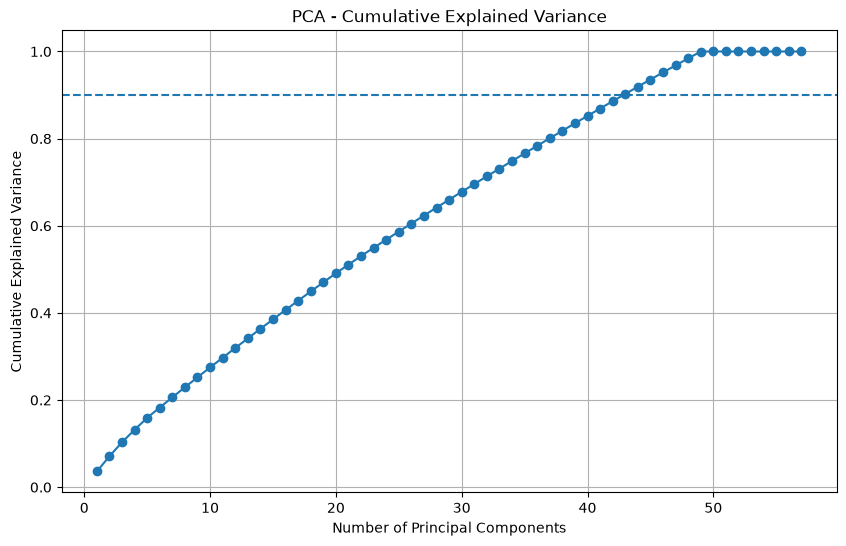

In [54]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(0.90, linestyle="--")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)

plt.show()

In [55]:
pca_final = PCA(n_components=43)

X_pca_final = pca_final.fit_transform(X_scaled)

X_pca_final = pd.DataFrame(
    X_pca_final,
    columns=[f"PC{i}" for i in range(1, 44)],
    index=X_scaled.index
)

print("Original X Shape:", X_scaled.shape)
print("Final PCA Shape:", X_pca_final.shape)
print(
    "Variance Retained:",
    pca_final.explained_variance_ratio_.sum()
)

Original X Shape: (10000, 57)
Final PCA Shape: (10000, 43)
Variance Retained: 0.9025348688168054


In [56]:
print("Final PCA Shape:", X_pca_final.shape)
print("Missing Values:", X_pca_final.isnull().sum().sum())
print("Duplicate Rows:", X_pca_final.duplicated().sum())

print("Infinite Values:", np.isinf(X_pca_final).sum().sum())

print(
    "Variance Retained:",
    pca_final.explained_variance_ratio_.sum()
)

Final PCA Shape: (10000, 43)
Missing Values: 0
Duplicate Rows: 0
Infinite Values: 0
Variance Retained: 0.9025348688168054


## Model Training  

### (1.) K-Means Clustering 

Segment customers into distinct groups based on their **annual income and total spending behavior** to understand different customer value segments.

In [57]:
# Select features for K-Means

kmeans_features = [
    "Annual_Income",
    "Total_Amount_Spent"
]

X_kmeans = df[kmeans_features].copy()

X_kmeans.head()

,Annual_Income,Total_Amount_Spent
0,40175.23,1265.0
1,27979.68,1647.0
2,64747.68,1806.0
3,50185.85,1207.0
4,53163.09,934.0


In [58]:
# Check missing values

X_kmeans.isnull().sum()

Annual_Income         0
Total_Amount_Spent    0
dtype: int64

In [59]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler_kmeans = StandardScaler()

X_kmeans_scaled = scaler_kmeans.fit_transform(X_kmeans)

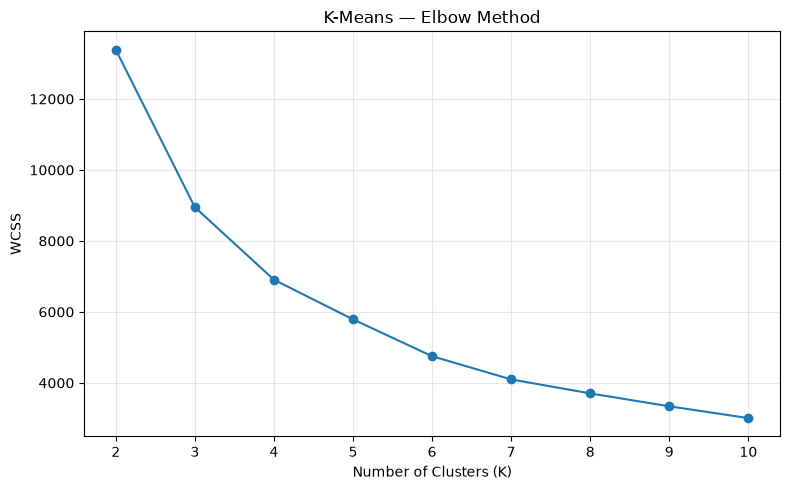

In [60]:
# Elbow Method

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_kmeans_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss, marker="o")

plt.title("K-Means — Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_kmeans_scaled)
    
    score = silhouette_score(X_kmeans_scaled, labels)
    silhouette_scores.append(score)

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: Silhouette Score = {score:.3f}")

K=2: Silhouette Score = 0.313
K=3: Silhouette Score = 0.335
K=4: Silhouette Score = 0.318
K=5: Silhouette Score = 0.315
K=6: Silhouette Score = 0.331
K=7: Silhouette Score = 0.330
K=8: Silhouette Score = 0.318
K=9: Silhouette Score = 0.320
K=10: Silhouette Score = 0.318


In [62]:
# Train Final K-Means Model

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_kmeans_scaled)

In [63]:
# Add Cluster Labels

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

df_kmeans["KMeans_Cluster"].value_counts().sort_index()

KMeans_Cluster
0    2725
1    2635
2    2374
3    2266
Name: count, dtype: int64

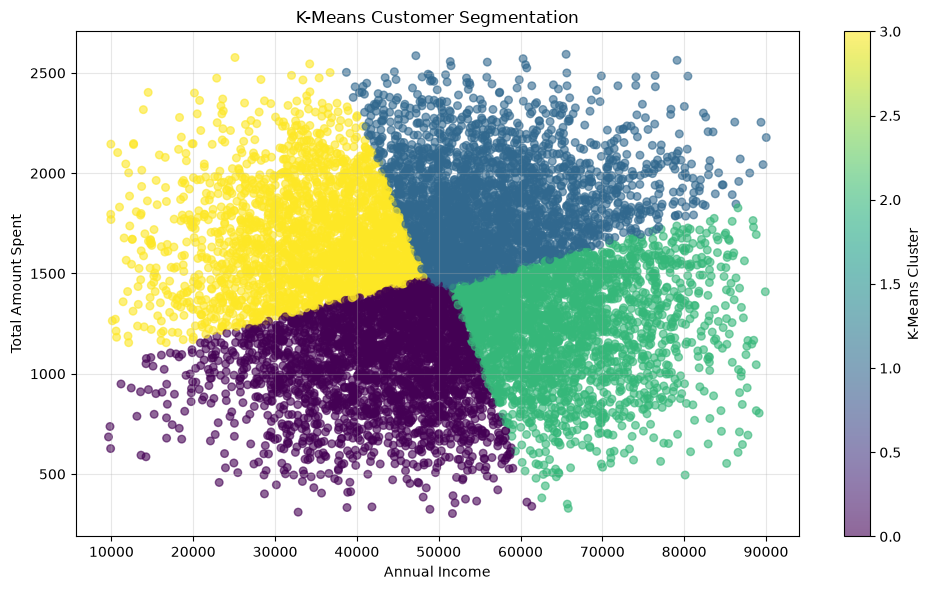

In [64]:
# Customer Segment Visualization

plt.figure(figsize=(10, 6))

plt.scatter(
    df_kmeans["Annual_Income"],
    df_kmeans["Total_Amount_Spent"],
    c=df_kmeans["KMeans_Cluster"],
    s=30,
    alpha=0.6
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Annual Income")
plt.ylabel("Total Amount Spent")
plt.colorbar(label="K-Means Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# Customer Segment Profile

kmeans_profile = (
    df_kmeans
    .groupby("KMeans_Cluster")[[
        "Annual_Income",
        "Total_Amount_Spent"
    ]]
    .mean()
    .round(2)
)

kmeans_profile

,Annual_Income,Total_Amount_Spent
KMeans_Cluster,,
0,42807.69,1057.40
1,56735.85,1849.04
2,65459.96,1231.12
3,34319.74,1676.58


### Final K-Means conclusion 

K-Means successfully segmented the 10,000 customers into four groups based on annual income and total spending. The resulting clusters represent different income–spending patterns, including lower-income/lower-spending, moderate-income/high-spending, high-income/moderate-spending, and lower-income/high-spending customers. This demonstrates how K-Means can be used to identify meaningful customer segments from numerical behavioral features.

## (2.) Hierarchical Clustering

Identify groups of customers with **similar annual income and spending patterns** using hierarchical clustering.

In [66]:
# Select features for Hierarchical Clustering

hierarchical_features = [
    "Annual_Income",
    "Total_Amount_Spent"
]

X_hierarchical = df[hierarchical_features].copy()

X_hierarchical.head()

,Annual_Income,Total_Amount_Spent
0,40175.23,1265.0
1,27979.68,1647.0
2,64747.68,1806.0
3,50185.85,1207.0
4,53163.09,934.0


In [67]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler_hierarchical = StandardScaler()

X_hierarchical_scaled = scaler_hierarchical.fit_transform(
    X_hierarchical
)

In [68]:
# Create Hierarchical Linkage

from scipy.cluster.hierarchy import linkage

hierarchical_linkage = linkage(
    X_hierarchical_scaled,
    method="ward"
)

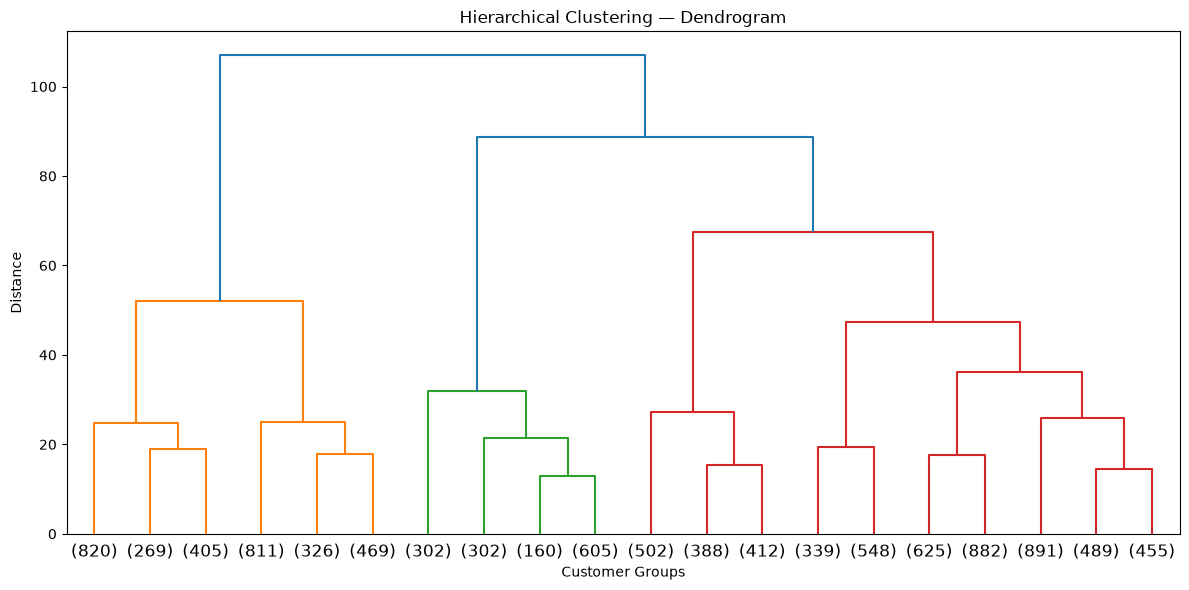

In [69]:
# Hierarchical Clustering Dendrogram

from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

dendrogram(
    hierarchical_linkage,
    truncate_mode="lastp",
    p=20
)

plt.title("Hierarchical Clustering — Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [70]:
# Train Final Hierarchical Clustering Model

from sklearn.cluster import AgglomerativeClustering

hierarchical_final = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical_final.fit_predict(
    X_hierarchical_scaled
)

In [71]:
# Add cluster labels

df_hierarchical = df.copy()

df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index()

Hierarchical_Cluster
0    5531
1    3100
2    1369
Name: count, dtype: int64

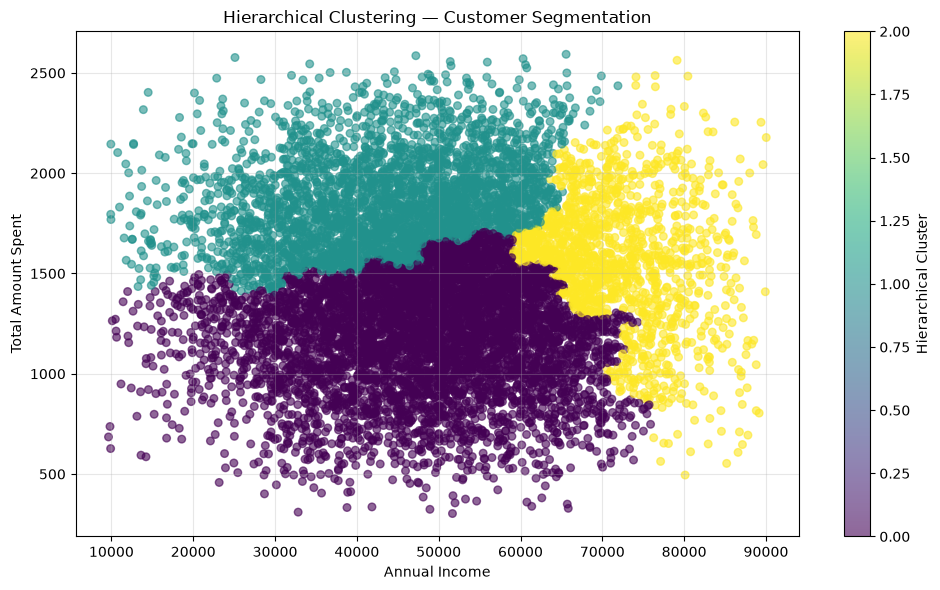

In [72]:
# Hierarchical Customer Segmentation

plt.figure(figsize=(10, 6))

plt.scatter(
    df_hierarchical["Annual_Income"],
    df_hierarchical["Total_Amount_Spent"],
    c=df_hierarchical["Hierarchical_Cluster"],
    s=30,
    alpha=0.6
)

plt.title("Hierarchical Clustering — Customer Segmentation")
plt.xlabel("Annual Income")
plt.ylabel("Total Amount Spent")
plt.colorbar(label="Hierarchical Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [73]:
# Customer Segment Profile

hierarchical_profile = (
    df_hierarchical
    .groupby("Hierarchical_Cluster")[[
        "Annual_Income",
        "Total_Amount_Spent"
    ]]
    .mean()
    .round(2)
)

hierarchical_profile

,Annual_Income,Total_Amount_Spent
Hierarchical_Cluster,,
0,48224.09,1182.05
1,43289.29,1867.16
2,71874.47,1569.99


### Hierarchical Clustering conclusion

Hierarchical clustering grouped the 10,000 customers into three segments based on annual income and total spending. The resulting groups represent moderate-income/lower-spending, lower-income/high-spending, and high-income/moderate-to-high-spending customer patterns. The dendrogram helped determine the number of groups, and the final segmentation demonstrates how hierarchical clustering can identify customer groups based on similarity.

## 3 — DBSCAN Clustering

Identify customers with **unusual income and spending patterns** using density-based clustering.


In [74]:
# Select features for DBSCAN

dbscan_features = [
    "Annual_Income",
    "Total_Amount_Spent"
]

X_dbscan = df[dbscan_features].copy()

X_dbscan.head()

,Annual_Income,Total_Amount_Spent
0,40175.23,1265.0
1,27979.68,1647.0
2,64747.68,1806.0
3,50185.85,1207.0
4,53163.09,934.0


In [75]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler_dbscan = StandardScaler()

X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

In [76]:
# Train DBSCAN

from sklearn.cluster import DBSCAN

dbscan_model = DBSCAN(
    eps=0.3,
    min_samples=10
)

dbscan_labels = dbscan_model.fit_predict(X_dbscan_scaled)

In [77]:
# DBSCAN Cluster Distribution

df_dbscan = df.copy()
df_dbscan["DBSCAN_Cluster"] = dbscan_labels

df_dbscan["DBSCAN_Cluster"].value_counts().sort_index()

DBSCAN_Cluster
-1      33
 0    9967
Name: count, dtype: int64

In [78]:
# Test different eps values

eps_values = [0.10, 0.15, 0.20, 0.25, 0.30]

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=10
    )
    
    labels = model.fit_predict(X_dbscan_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = (labels == -1).sum()
    
    print(
        f"eps={eps:.2f} | "
        f"Clusters={n_clusters} | "
        f"Noise={noise_count} "
        f"({noise_count / len(labels) * 100:.2f}%)"
    )

eps=0.10 | Clusters=12 | Noise=1066 (10.66%)
eps=0.15 | Clusters=3 | Noise=371 (3.71%)
eps=0.20 | Clusters=1 | Noise=185 (1.85%)
eps=0.25 | Clusters=1 | Noise=79 (0.79%)
eps=0.30 | Clusters=1 | Noise=33 (0.33%)


In [79]:
# Final DBSCAN Model

dbscan_final = DBSCAN(
    eps=0.15,
    min_samples=10
)

dbscan_labels = dbscan_final.fit_predict(X_dbscan_scaled)

df_dbscan["DBSCAN_Cluster"] = dbscan_labels

In [80]:
# Final DBSCAN Cluster Distribution

df_dbscan["DBSCAN_Cluster"].value_counts().sort_index()

DBSCAN_Cluster
-1     371
 0    9604
 1      17
 2       8
Name: count, dtype: int64

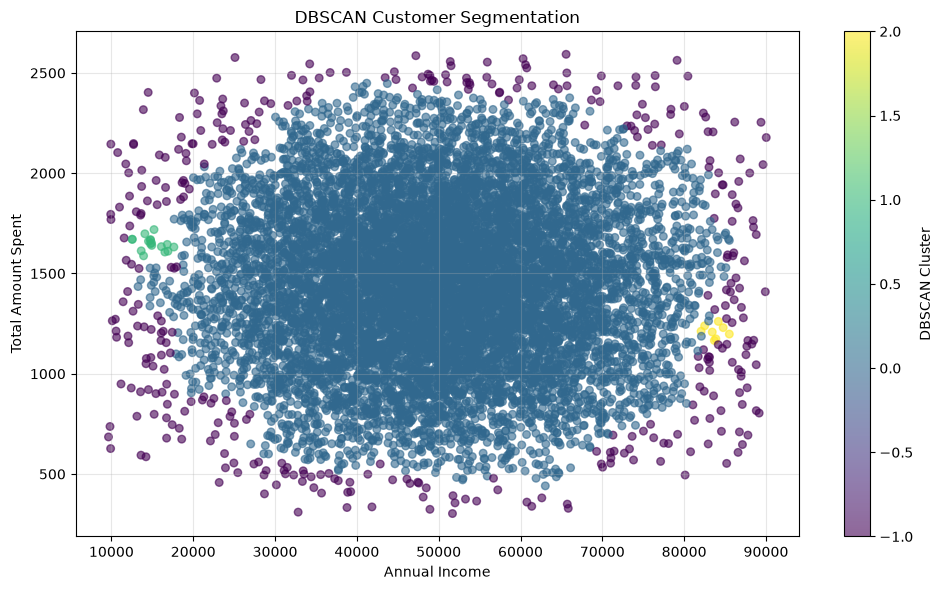

In [81]:
# Cell 8 — DBSCAN Customer Segmentation

plt.figure(figsize=(10, 6))

plt.scatter(
    df_dbscan["Annual_Income"],
    df_dbscan["Total_Amount_Spent"],
    c=df_dbscan["DBSCAN_Cluster"],
    s=30,
    alpha=0.6
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Annual Income")
plt.ylabel("Total Amount Spent")
plt.colorbar(label="DBSCAN Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [82]:
# DBSCAN Customer Profile

dbscan_profile = (
    df_dbscan
    .groupby("DBSCAN_Cluster")[[
        "Annual_Income",
        "Total_Amount_Spent"
    ]]
    .mean()
    .round(2)
)

dbscan_profile

,Annual_Income,Total_Amount_Spent
DBSCAN_Cluster,,
-1,47928.13,1470.51
0,50043.14,1446.50
1,14981.81,1648.47
2,83756.18,1211.00


## DBSCAN final conclusion 

DBSCAN identified one dominant dense customer group along with two small density-based groups and a set of noise observations. The small groups represent customers with notably low or high income compared with the dominant group, while the noise observations represent customers that do not belong to sufficiently dense regions. This demonstrates how DBSCAN can identify unusual income–spending patterns without requiring a predefined number of clusters.